In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import torch
import torch.nn as nn
import seaborn as sns

all_data = {}

# Το gain ειναι πάντα 100 και το baseline 0
fhr_gain = 100
fhr_baseline = 0
fs = 4

for dat_file in glob.glob("data/all_data/*.dat"):
    id = dat_file.split("/")[-1].split(".")[0]
    data = np.fromfile(dat_file, dtype=np.int16)
    fhr_signal = (data[0::2]- fhr_baseline) / fhr_gain
    uc_signal = data[1::2]
    time = np.arange(len(uc_signal)) / fs
    all_data[int(id)] = {"fhr_signal": fhr_signal, "uc_signal": uc_signal, "time": time}

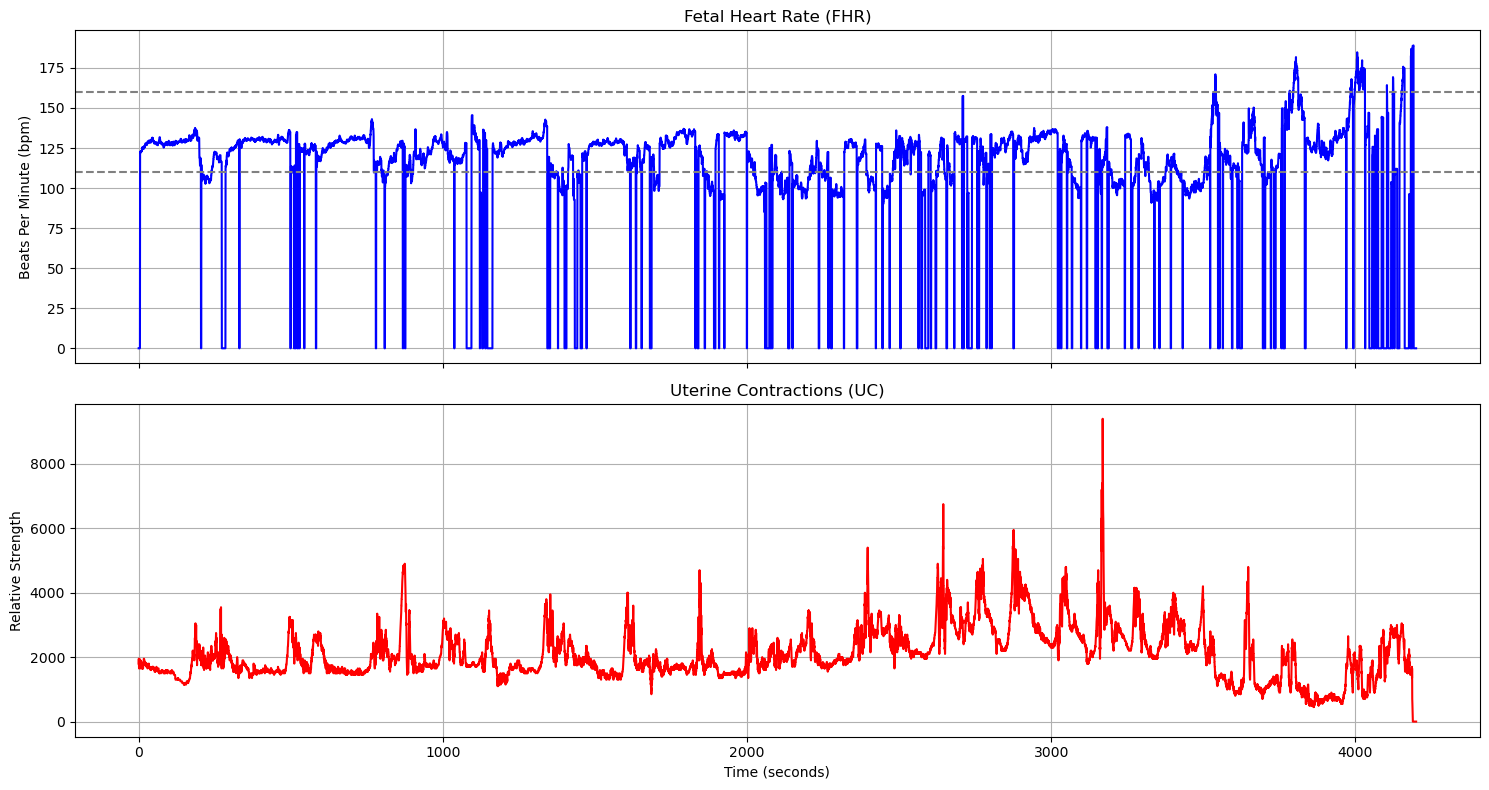

In [2]:
sample = 1008

# Create the plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Plot Fetal Heart Rate
ax1.plot(all_data[sample]["time"], all_data[sample]["fhr_signal"], color='blue')
ax1.set_title('Fetal Heart Rate (FHR)')
ax1.set_ylabel('Beats Per Minute (bpm)')
# Add lines for the normal FHR range
ax1.axhline(y=110, color='gray', linestyle='--')
ax1.axhline(y=160, color='gray', linestyle='--')
ax1.grid(True)

# Plot Uterine Contractions
ax2.plot(all_data[sample]["time"], all_data[sample]["uc_signal"], color='red')
ax2.set_title('Uterine Contractions (UC)')
ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('Relative Strength')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [3]:
fhr_vals = []
uc_vals = []

for key, val in all_data.items():
    fhr_vals.append(val["fhr_signal"])
    uc_vals.append(val["uc_signal"])

In [5]:
def calculate_zero_stats(fhr):
    fhr = np.asarray(fhr)
    size = len(fhr)
    lengths = []
    lengths_normalized = []
    length = 0

    for val in fhr:
        if val == 0:
            length += 1
        elif length > 0:
            # End of a zero run
            lengths.append(length)
            lengths_normalized.append(length / size)
            length = 0

    # Handle case where signal ends with zeros
    if length > 0:
        lengths.append(length)
        lengths_normalized.append(length / size)

    return size, np.array(lengths), np.array(lengths_normalized)



In [6]:
sizes = []
lens = []
norm_lens = []

norm_means = []
norm_mins = []
norm_maxs = []
norm_stds = []
norm_medians = []

percents = []
for fhr in fhr_vals:
    size, lengths, lengths_normalized = calculate_zero_stats(fhr)


    norm_min, norm_max, norm_std, norm_mean = 0, 0, 0, 0
    if len(lengths_normalized) > 0:
        norm_min =lengths_normalized.min().item()
        norm_max =lengths_normalized.max().item()
        norm_std =lengths_normalized.std().item()
        norm_mean = lengths_normalized.mean().item()
        norm_median = np.median(lengths_normalized).item()

    norm_means.append(norm_mean)
    norm_mins.append(norm_min)
    norm_maxs.append(norm_max)
    norm_stds.append(norm_std)
    norm_medians.append(norm_median)

    sizes.append(size)
    lens.append(lengths)
    norm_lens.append(lengths_normalized)
    percents.append(sum(lengths_normalized))

norm_means = np.array(norm_means)
norm_mins = np.array(norm_mins)
norm_maxs = np.array(norm_maxs)
norm_stds = np.array(norm_stds)
norm_medians = np.array(norm_medians)



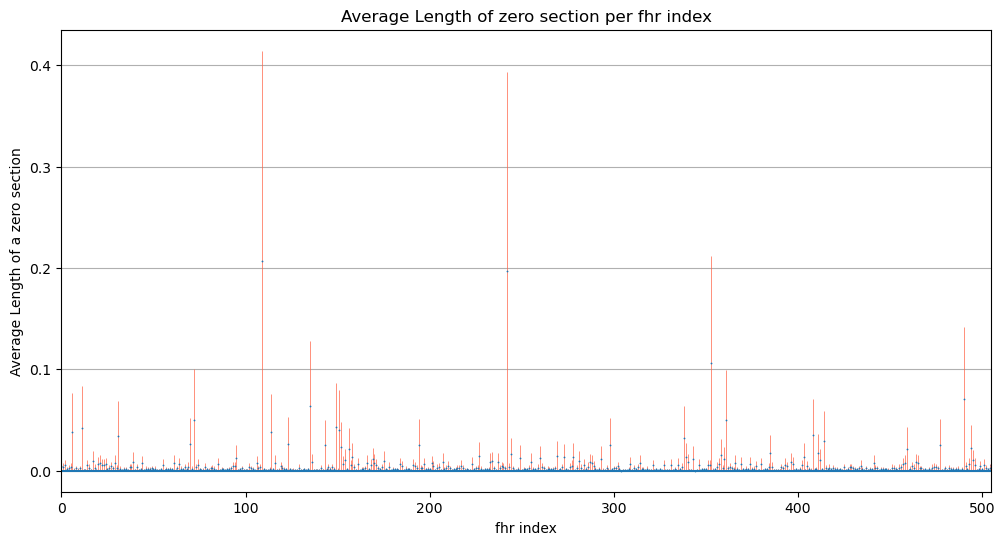

In [7]:
# yerr plot με mean και std
x = range(len(norm_means))
plt.figure(figsize=(12,6))
plt.errorbar(x, norm_means, yerr=norm_means, fmt='o', ecolor='tomato',
             capsize=0,               
             elinewidth=0.5,        
             markeredgewidth=0,    
             markersize=1.3)

plt.xlabel('fhr index')
plt.ylabel('Average Length of a zero section')
plt.title('Average Length of zero section per fhr index')
plt.grid(axis="y")
plt.xlim(x[0], x[-1])
# plt.savefig("plots/quad_time_yerr_k_3", bbox_inches ="tight")
plt.axhline(y=0)
plt.show()

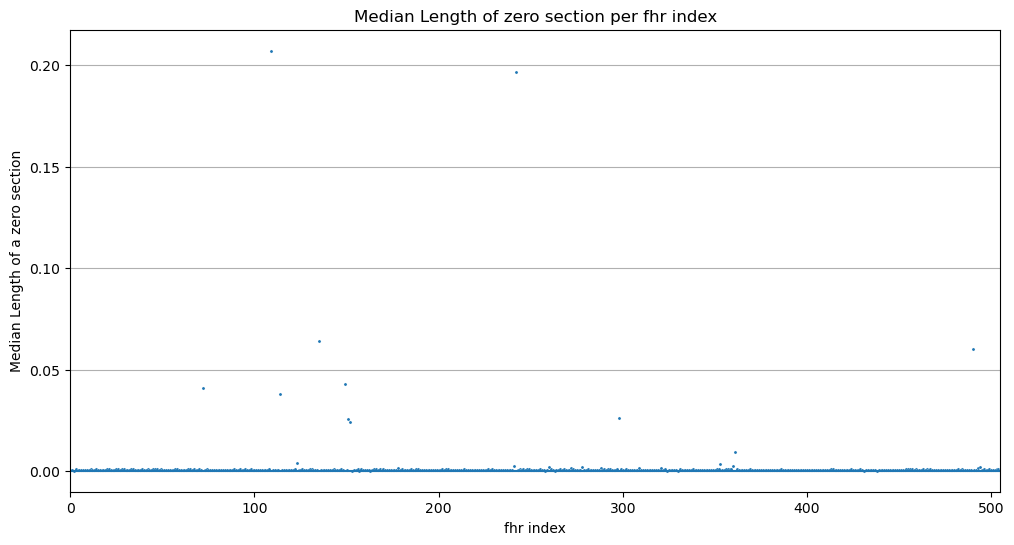

In [8]:
# Διάγραμμα με τα medians
x = range(len(norm_medians))
plt.figure(figsize=(12,6))
sns.scatterplot(x = x, y = norm_medians, s = 5)

plt.xlabel('fhr index')
plt.ylabel('Median Length of a zero section')
plt.title('Median Length of zero section per fhr index')
plt.grid(axis="y")
plt.xlim(x[0], x[-1])
# plt.savefig("plots/median_quad_time_yerr_k_3", bbox_inches ="tight")
plt.axhline(y=0)
plt.show()

(0.0, 0.005)

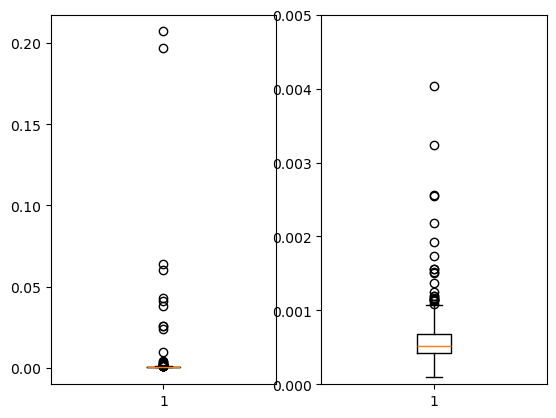

In [9]:
# too much outliers, meaning those values cant even be restored, probably stiched together
fig, axes = plt.subplots(ncols=2)

axes[0].boxplot(norm_medians)
axes[1].boxplot(norm_medians)
axes[1].set_ylim(0, 0.005)

In [10]:
# The range will be median 50% quantile

minimum = np.quantile(norm_medians, 0.25)
maximum = np.quantile(norm_medians, 0.75)

In [11]:
filtered = norm_medians[(norm_medians >= minimum) & (norm_medians <= maximum)]

(array([32., 30., 25., 38., 30., 18., 29.,  9., 20., 21.]),
 array([0.00041667, 0.00044271, 0.00046875, 0.00049479, 0.00052083,
        0.00054688, 0.00057292, 0.00059896, 0.000625  , 0.00065104,
        0.00067708]),
 <BarContainer object of 10 artists>)

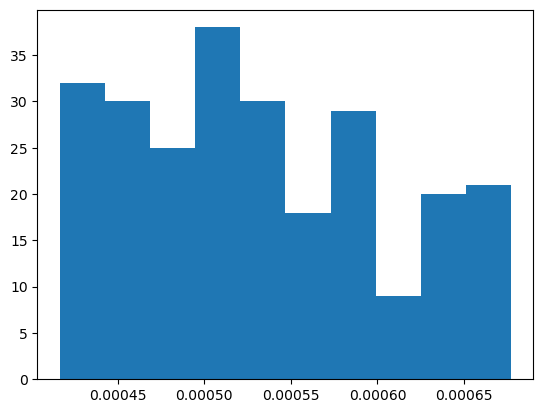

In [12]:
plt.hist(filtered)

In [13]:
np.std(sizes)

np.float64(1812.5202963468266)

In [14]:
growth = np.median(sizes)/2048

In [15]:

print(growth*filtered.mean(), growth*filtered.std())

0.004330473500925825 0.0006158383567016473


In [16]:
print(f"Median length of missing region {np.mean(norm_medians)}")

Median length of missing region 0.002023402544625936


(array([480.,  17.,   4.,   2.,   0.,   1.,   0.,   0.,   0.,   2.]),
 array([0.        , 0.02071795, 0.0414359 , 0.06215385, 0.08287179,
        0.10358974, 0.12430769, 0.14502564, 0.16574359, 0.18646154,
        0.20717949]),
 <BarContainer object of 10 artists>)

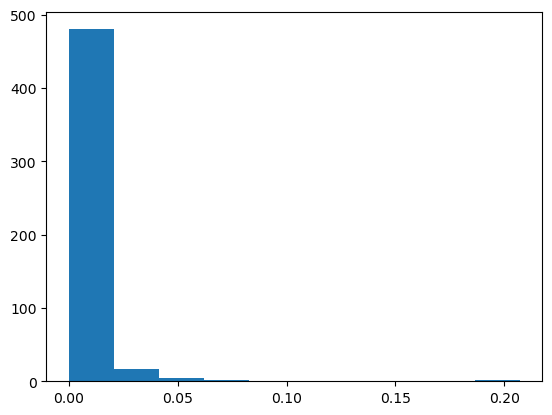

In [17]:
plt.hist(norm_means)

(array([56., 42., 26., 34., 41., 36., 35., 45., 39., 32., 31., 24., 20.,
        12., 10.,  5.,  4.,  5.,  6.,  3.]),
 array([0.        , 0.02590782, 0.05181564, 0.07772346, 0.10363128,
        0.12953911, 0.15544693, 0.18135475, 0.20726257, 0.23317039,
        0.25907821, 0.28498603, 0.31089385, 0.33680168, 0.3627095 ,
        0.38861732, 0.41452514, 0.44043296, 0.46634078, 0.4922486 ,
        0.51815642]),
 <BarContainer object of 20 artists>)

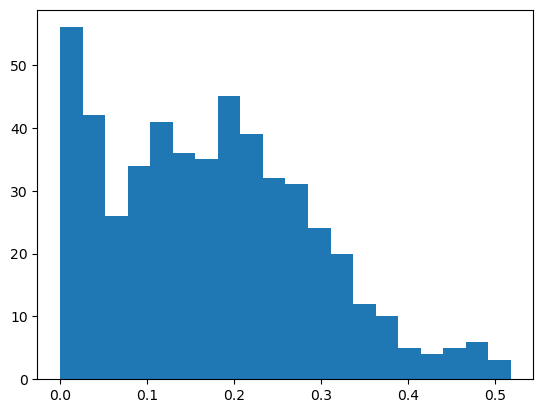

In [18]:
plt.hist(percents, bins=20)

(array([  3.,   0., 109.,   1., 156.,   3.,   0.,  83.,   2.,  72.,   5.,
          0.,  31.,   2.,  39.]),
 array([14400.        , 14881.33333333, 15362.66666667, 15844.        ,
        16325.33333333, 16806.66666667, 17288.        , 17769.33333333,
        18250.66666667, 18732.        , 19213.33333333, 19694.66666667,
        20176.        , 20657.33333333, 21138.66666667, 21620.        ]),
 <BarContainer object of 15 artists>)

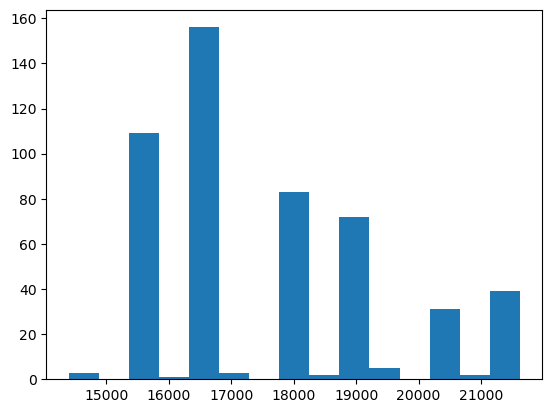

In [19]:
plt.hist(sizes, bins=15)